<a href="https://colab.research.google.com/github/habiba-abdelwahab/AIE231-Neural-Networks-Project/blob/main/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Problem framing and EDA (HAM10000)
Owner: Baseline & Analysis Engineer (spec 3.1). Milestones 1 and 2.

**How to run on Colab:** Runtime → Change runtime type → GPU, then run all cells.
Before running: upload the project zip to the Colab **Files** panel (or put the unzipped folder in Google Drive). The first cell finds it; the second downloads the data (about 3 GB).

In [1]:
# --- Setup: works on Colab and locally. Run this cell first. ---
# It finds the project folder (the one that has src/ and configs/), moves into it,
# and adds it to sys.path so that `from src ... import ...` works.
import os, sys, glob, zipfile

def is_root(path):
    """A folder is the project root if it contains both src/ and configs/."""
    return os.path.isdir(os.path.join(path, "src")) and os.path.isdir(os.path.join(path, "configs"))

def find_root():
    """Look in the current folder, its parent, /content and Google Drive (2 levels deep)."""
    here = os.getcwd()
    candidates = [here, os.path.dirname(here)]
    for base in ["/content", "/content/drive/MyDrive"]:
        candidates += glob.glob(base + "/*") + glob.glob(base + "/*/*")
    return next((c for c in candidates if is_root(c)), None)

IN_COLAB = "google.colab" in sys.modules
root = find_root()

# Colab, option 1: you uploaded the project zip to the Files panel (/content).
if root is None and IN_COLAB:
    for z in glob.glob("/content/*.zip"):
        zipfile.ZipFile(z).extractall("/content/project")
        print("unzipped", z)
    root = find_root()

# Colab, option 2: the project is in your Google Drive.
if root is None and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    root = find_root()

if root is None:
    raise FileNotFoundError("Project folder not found. Upload the project zip to the Colab Files "
                            "panel, or put the project folder in Google Drive, then run this cell again.")
os.chdir(root)
sys.path.insert(0, root)
print("project root:", root)

unzipped /content/ham10000-project.zip
project root: /content/project


In [2]:
# Download HAM10000 (about 3 GB, only the first time).
!pip install -q kagglehub
!python data/download.py

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Done: /content/project/data/raw/ham10000


## 1. Problem framing

**User:** a dermatologist or GP who photographs a skin lesion with a dermatoscope.
**Prediction:** which of 7 diagnoses the lesion most likely is (akiec, bcc, bkl, df, mel, nv, vasc), with a confidence.
**Cost of errors:** missing a melanoma (calling it a harmless mole) can delay treatment of a deadly cancer, so a false negative on `mel`, `bcc` or `akiec` is far worse than a false alarm, which only costs an extra biopsy.
This is a course project and **not a diagnostic tool**.

| Item | Choice | Why |
|---|---|---|
| Input | RGB image resized to 128 × 128 × 3, pixels in [0, 1] | originals are 600 × 450; 128 keeps one run under 30 min on Colab (GUESS, check with timing) |
| Output | 7 probabilities (softmax) | one class per lesion, classes are mutually exclusive |
| Loss | sparse categorical cross-entropy, with class weights | standard for softmax multi-class; weights counter the imbalance |
| **Primary metric** | **balanced accuracy** (mean of the 7 per-class recalls) | "always nv" already gets ~67 % accuracy but only 14 % balanced accuracy; it is also the official ISIC 2018 metric for this data |
| Secondary | melanoma recall, macro-F1, per-class recall, ROC-AUC | melanoma recall measures the most expensive error directly |

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from src.config import load_config
from src import data as D

cfg = load_config("configs/base.yaml")
CLASSES = cfg["data"]["classes"]
raw = D.load_metadata(cfg)
print(raw.shape)
raw.head()

(10015, 9)


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/project/data/raw/ham10000/HAM10000_im...,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/project/data/raw/ham10000/HAM10000_im...,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/project/data/raw/ham10000/HAM10000_im...,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/project/data/raw/ham10000/HAM10000_im...,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/project/data/raw/ham10000/HAM10000_im...,2


## 2. Class distribution (imbalance)

dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64 
imbalance ratio (largest / smallest): 58.3


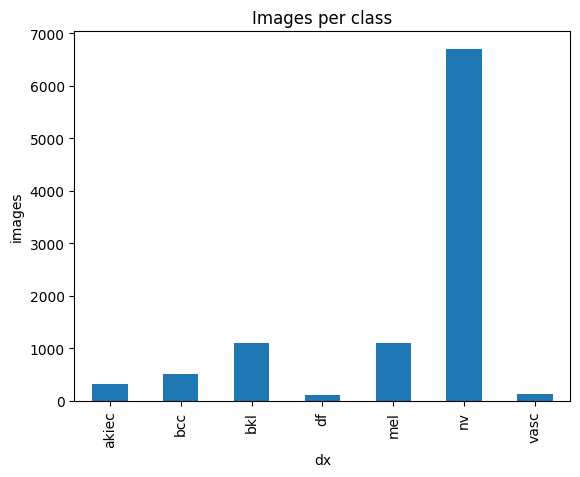

In [4]:
counts = raw["dx"].value_counts().reindex(CLASSES)
print(counts, "\nimbalance ratio (largest / smallest):", round(counts.max() / counts.min(), 1))
counts.plot.bar(title="Images per class"); plt.ylabel("images"); plt.show()

## 3. Missing values, 'unknown' entries and missing files

In [5]:
print("missing values per column:\n", raw.isna().sum())
print("\n'unknown' per column:\n", (raw == "unknown").sum())
print("\nduplicate image_id rows:", raw["image_id"].duplicated().sum())

missing values per column:
 lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
path             0
label            0
dtype: int64

'unknown' per column:
 lesion_id         0
image_id          0
dx                0
dx_type           0
age               0
sex              57
localization    234
path              0
label             0
dtype: int64

duplicate image_id rows: 0


## 4. Several images per lesion → leakage risk
If two photos of the same lesion land in train and test, the test score is too optimistic.

In [6]:
per_lesion = raw.groupby("lesion_id").size()
print("lesions:", per_lesion.size, "| images:", len(raw))
print(per_lesion.value_counts().sort_index().rename("lesions with this many images"))

lesions: 7470 | images: 10015
1    5514
2    1423
3     490
4      34
5       5
6       4
Name: lesions with this many images, dtype: int64


## 5. How the diagnosis was confirmed (label quality)

In [7]:
pd.crosstab(raw["dx"], raw["dx_type"]).reindex(CLASSES)
# histo = biopsy (strongest label). follow_up / consensus / confocal are weaker → possible label noise.

dx_type,confocal,consensus,follow_up,histo
dx,,,,
akiec,0,0,0,327
bcc,0,0,0,514
bkl,69,264,0,766
df,0,60,0,55
mel,0,0,0,1113
nv,0,503,3704,2498
vasc,0,75,0,67


## 6. Age, sex and body location

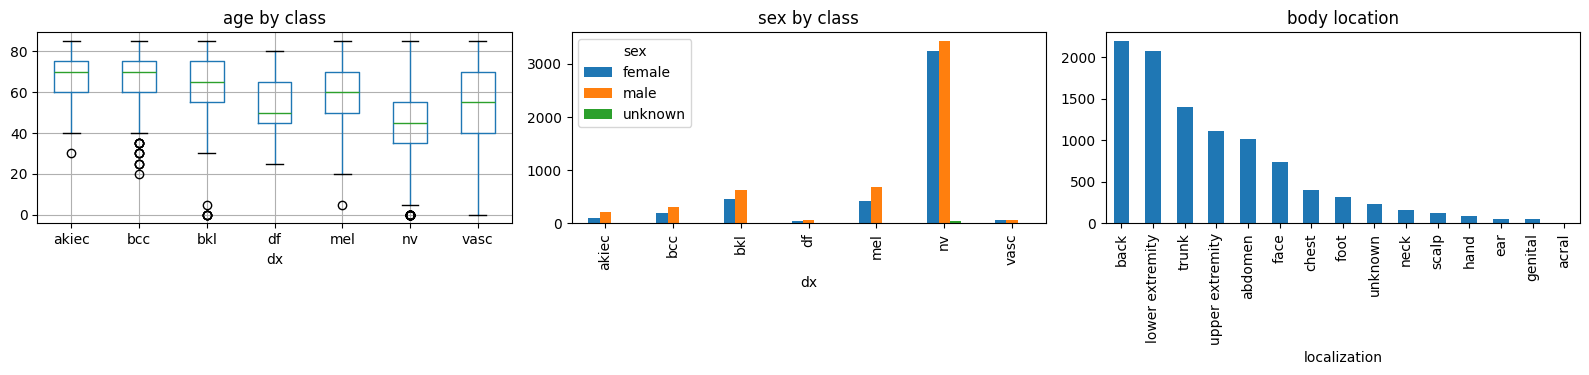

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw.boxplot(column="age", by="dx", ax=ax[0]); ax[0].set_title("age by class")
pd.crosstab(raw["dx"], raw["sex"]).plot.bar(ax=ax[1], title="sex by class")
raw["localization"].value_counts().plot.bar(ax=ax[2], title="body location")
plt.suptitle(""); plt.tight_layout(); plt.show()

## 7. Image size and brightness

image sizes (width, height):
 (600, 450)    210
Name: count, dtype: int64


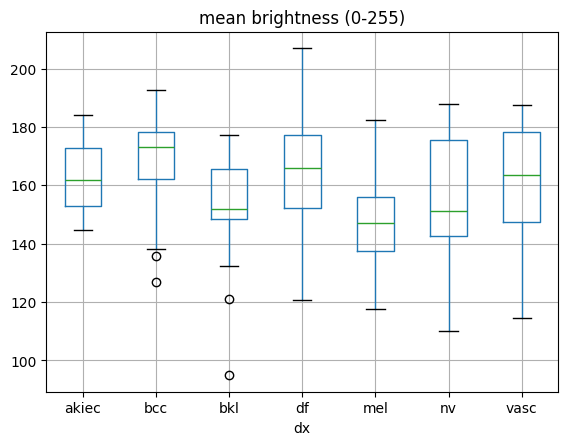

In [9]:
sample = raw.groupby("dx").sample(30, random_state=0, replace=True)
sizes = pd.Series([Image.open(p).size for p in sample["path"]]).value_counts()
print("image sizes (width, height):\n", sizes)
sample["brightness"] = [np.asarray(Image.open(p).convert("L")).mean() for p in sample["path"]]
sample.boxplot(column="brightness", by="dx"); plt.suptitle(""); plt.title("mean brightness (0-255)"); plt.show()

## 8. Sample images per class

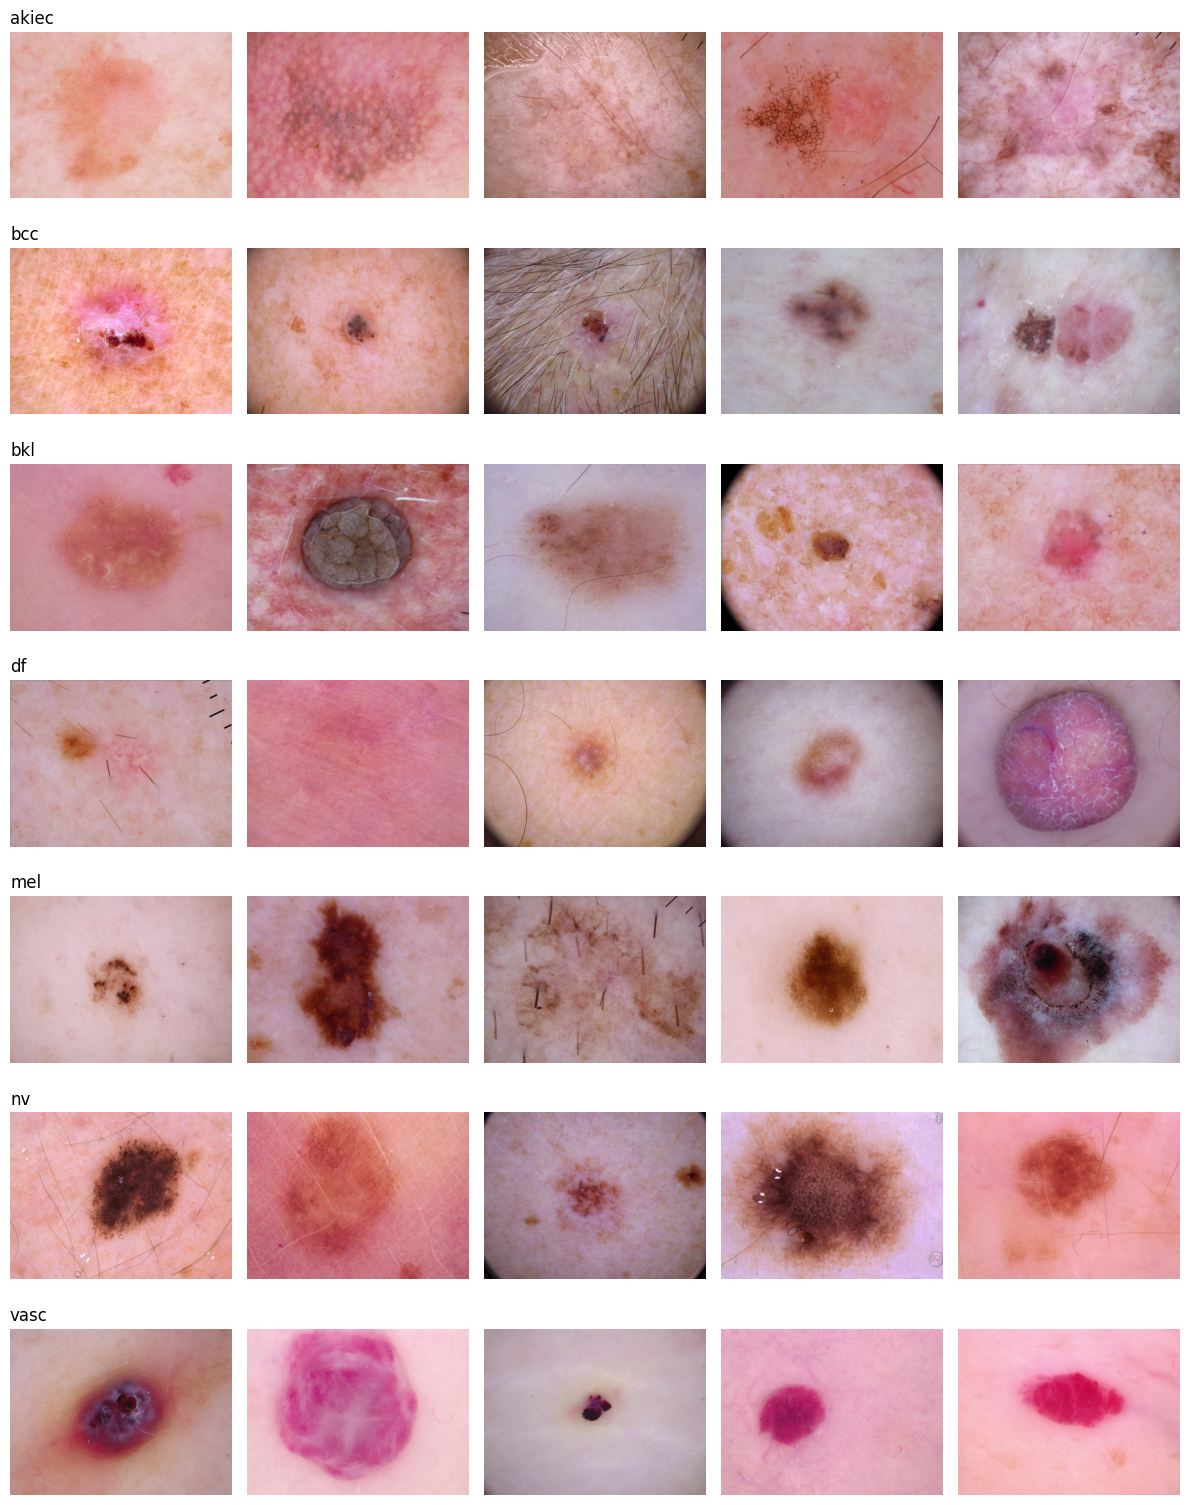

In [10]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 2.2 * len(CLASSES)))
for r, c in enumerate(CLASSES):
    rows = raw[raw["dx"] == c].sample(5, random_state=1, replace=True)
    for k, p in enumerate(rows["path"]):
        axes[r, k].imshow(Image.open(p)); axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## 9. Findings → modelling decisions
Expected values come from the dataset paper. **Check every number against your outputs above and fix the table if they differ.**

| # | Finding (expected) | Decision |
|---|---|---|
| 1 | Strong imbalance: nv ≈ 6,705 of 10,015 images (67 %), df ≈ 115 (1 %); ratio ≈ 58 : 1 | Balanced accuracy as main metric, class weights in the loss, report per-class recall |
| 2 | ≈ 7,470 lesions for 10,015 images; some lesions have up to ~6 photos | Split by `lesion_id` so no lesion is in two splits |
| 3 | `age` has ~57 missing values; `sex` and `localization` contain "unknown" | Models use images only, so no imputation needed for training; age filled with median only for plots |
| 4 | All images are 600 × 450 RGB | Resize to 128 × 128 (fits Colab time); try 224 for the VGG16 models |
| 5 | Lighting and colour vary between images; lesions have no fixed orientation | Augment train only: flips, rotation, zoom, contrast |
| 6 | Over half the labels are not biopsy-confirmed (follow-up / consensus) | Expect some label noise; check it in the error analysis |
| 7 | mel, bkl and nv look alike in many samples | Expect most confusion between these three; inspect it in error analysis |

## 10. Milestone 2 check: leak-free split, class weights, augmentation

In [11]:
splits = D.prepare(cfg)                     # clean + lesion-level stratified 70/15/15
D.split_summary(splits, CLASSES)            # class % should be almost equal in each column

clean(): kept 10015 of 10015 rows


,train,val,test
dx,,,
akiec,0.033,0.029,0.034
bcc,0.052,0.049,0.051
bkl,0.110,0.114,0.105
df,0.011,0.012,0.015
mel,0.110,0.115,0.112
nv,0.671,0.666,0.668
vasc,0.014,0.015,0.015
n_images,7054.000,1464.000,1497.000


In [12]:
weights = D.class_weights(splits["train"], len(CLASSES))   # from TRAIN only
pd.Series(weights, index=CLASSES).round(2)

,0
akiec,NaN
bcc,NaN
bkl,NaN
df,NaN
mel,NaN
nv,NaN
vasc,NaN


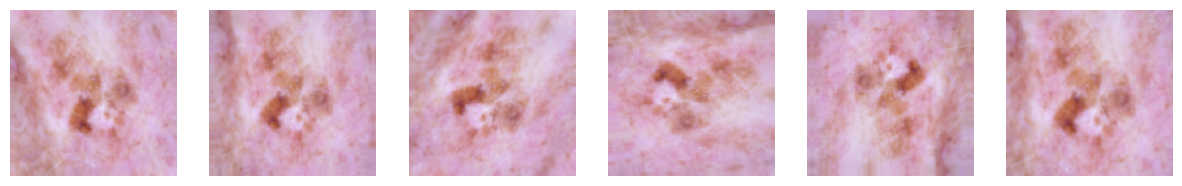

In [13]:
# Show the same training image 6 times with random augmentation.
import tensorflow as tf
augment = D.build_augmentation(cfg)
img = D.load_image(splits["train"]["path"].iloc[0], cfg["data"]["image_size"])
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax in axes:
    ax.imshow(augment(img[None], training=True)[0].numpy().clip(0, 1)); ax.axis("off")
plt.show()

## 11. Baselines (spec 3.3), scored on the validation set
The test set stays locked until the final model is chosen. Each run is added to `experiments/experiments.csv`.

In [14]:
!python -m src.train --config configs/baseline_majority.yaml
!python -m src.train --config configs/baseline_logreg.yaml
pd.read_csv("experiments/experiments.csv").tail(2)

I0000 00:00:1795719336.798208    4662 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795719340.130581    4662 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
clean(): kept 10015 of 10015 rows
val recall per class: akiec=0.00  bcc=0.00  bkl=0.00  df=0.00  mel=0.00  nv=1.00  vasc=0.00
[20261126-185731-9224] majority  val: balanced_accuracy=0.143  macro_f1=0.114  accuracy=0.666  recall_mel=0.000
I0000 00:00:1795719454.799269    5143 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795719457.756505    5143 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
clean(): kept 10015 of 10015 rows
val recall per class: akiec=0.30  bcc=0.47  bkl=0.45  df=0.06  mel=0.45  nv=0.65  vasc=0.55
[20261126-190049-7067] logreg  val: balanced_accuracy=0.417  macro_f1=0.350  accuracy=0.574  recall_mel=0.446


,run_id,date,author,config,model,seed,hyperparameters,params,train_time_s,epochs_run,train_balanced_accuracy,val_balanced_accuracy,val_macro_f1,val_accuracy,val_recall_mel,notes
0,20261126-185731-9224,2026-11-26T18:57:31+00:00,TODO-your-github-login,configs/baseline_majority.yaml,majority,42,"{""name"": ""majority"", ""optimizer"": ""adam"", ""lea...",NaN,109.6,NaN,0.1429,0.1429,0.1142,0.6660,0.0000,reference configuration
1,20261126-190049-7067,2026-11-26T19:00:49+00:00,TODO-your-github-login,configs/baseline_logreg.yaml,logreg,42,"{""name"": ""logreg"", ""optimizer"": ""adam"", ""learn...",NaN,190.1,NaN,0.8478,0.4172,0.3500,0.5738,0.4464,reference configuration


The majority baseline predicts nv for every image: it reaches 66.6% accuracy but only 0.143 balanced accuracy and 0 melanoma recall, which shows why accuracy is misleading here. Logistic regression on 32×32 pixels reaches 0.417 balanced accuracy (macro-F1 0.350) and finds 44.6% of melanomas. It does best on nv (recall 0.65) and vasc (0.55), and worst on df (0.06) and akiec (0.30), the two rarest and least distinctive classes. Its training balanced accuracy is 0.847, far above validation, so it overfits the raw pixels; a CNN that learns local patterns should beat 0.417.